# Genotype Filtering and Reference Alignment


- Which measured genotypes meet the study’s filtering and reference-alignment requirements?
- PLINK 1.9 filtering, CanFam3.1 to CanFam4 alignment, and additional diagnostic screens examine the prepared LR and GSP cohorts under both control schemes.
- These procedures assess genotype completeness, allele frequency, Hardy–Weinberg equilibrium, coordinate and allele compatibility, heterozygosity, X-marker sex agreement, and case–control missingness.
- They do not establish biological effects or imputation accuracy; diagnostic flags alone do not determine exclusions or change recorded sex.


### (Initialization) Import Directory-Free Helpers


In [1]:
# Locate the repository and load the helpers used to run or verify the genotype preparation stages.

from pathlib import Path
import importlib
import sys

study_root = next(p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "scripts/notebook_support.py").exists())
sys.path.insert(0, str(study_root / "scripts"))
read_json = importlib.import_module("notebook_support").read_json
study_path = importlib.import_module("notebook_support").study_path
verify_datasets = importlib.import_module("notebook_support").verify_datasets
require_saved = importlib.import_module("notebook_review").require_saved
run_script = importlib.import_module("notebook_support").run_script

### PLINK 1.9: Filtering Information

| Filter | Cutoff | What It Means |
| :---: | :---: | :---: |
| Missing measurements per dog | No more than 10% | Exclude a dog if more than one in ten eligible markers lack a genotype. |
| Missing measurements per marker | No more than 10% | Exclude a marker if its genotype is missing for more than one in ten retained dogs. |
| Minor allele frequency | At least 2.5% | Require the less common genetic alternative to meet this frequency threshold. |
| Hardy–Weinberg equilibrium | Exclude p < 0.00001 | Exclude markers whose genotype proportions depart strongly from a simple population expectation. |


### Filtered Dog Summary

| Scheme | Breed | Controls | Behavioral Cases | Total Dogs | Retained Markers |
| :---: | :---: | :---: | :---: | :---: | :---: |
| A | GSP | 96 | 9 | 105 | 168,167 |
| B | GSP | 107 | 9 | 116 | 168,167 |
| A | LR | 39 | 7 | 46 | 171,522 |
| B | LR | 41 | 7 | 48 | 171,522 |


### Filtered Marker Summary

| Filtering Step | GSP Markers | LR Markers |
| :---: | :---: | :---: |
| Starting array markers | 229,991 | 229,991 |
| Eligible autosomal SNPs | 220,807 | 220,807 |
| After the marker missing-data cutoff | 220,445 | 220,357 |
| After the allele-frequency cutoff | 168,905 | 171,572 |
| After the Hardy–Weinberg cutoff | 168,167 | 171,522 |


### CanFam3.1 to CanFam4 Marker Alignment Information

- CanFam3.1 coordinates and allele labels are converted to CanFam4 for Dog10K comparison.
- CanineHD sequence annotations resolve strand orientation, including A/T and C/G markers.
- Alignment prepares markers for imputation.


### CanFam3.1 to CanFam4 Marker Alignment Summary

- Both schemes retain the same aligned markers within each breed and all dogs remain included. Retained calls agree with QC inputs and an independent PLINK export. Unresolved markers remain in the original files.

| Breed | Markers Passing QC | Markers Aligned | A/T Or C/G Markers Retained |
| :---: | :---: | :---: | :---: |
| GSP | 168,167 | 165,064 | 8,202 |
| LR | 171,522 | 168,341 | 8,389 |


### Filtering and Imputation Limitations

- Hardy–Weinberg departures can reflect breed history or relatedness.
- Frequency cutoffs do not guarantee enough allele copies among cases.
- 12 of 18 historical (2013TSA) targets remain in each breed after QC and alignment.
- Excluded targets do not count as failed replications.


### (Data Filtering) PLINK 1.9 Dog and Marker Filtering
- *array_qc.py*
### (Consistency Check) Review Filtered Data

In [2]:
# Run genotype filtering only if its saved manifest is absent, then verify the completed datasets.
# This reuses existing QC results while checking that the recorded files are intact.

qc_path = study_root / "data/02-qc/manifest.private.json"
require_saved(qc_path)
# if not qc_path.exists():
#     from notebook_support import plink_environment
#     environment_file = plink_environment(study_root)
#     run_script(study_root, "array_qc.py", "--root", study_root,
#                "--environment", environment_file)
qc = read_json(qc_path)
assert qc["status"] == "complete"
verify_datasets(study_root, qc)
print("QC datasets verified:", len(qc["datasets"]))

QC datasets verified: 4


### (Acquisition) Optional CanFam4 Reference Download
- Download references files for imputation and CanFam3.1 -> CanFam4 conversion
- *download_imputation_assets.py*
- *download_reference_genomes.py*

In [3]:
# Optionally download the public reference files needed for coordinate and allele alignment.
# Downloads stay disabled by default when reviewing the completed study.

download_missing_resources = False
if download_missing_resources:
#     run_script(study_root, "download_imputation_assets.py")
#     run_script(study_root, "download_reference_genomes.py")
    manifest_file = study_root / "data/02-reference/array-manifests/caninehd_b.csv"
#     if not manifest_file.exists():
#         from urllib.request import urlretrieve
#         manifest_file.parent.mkdir(parents=True, exist_ok=True)
#         urlretrieve("https://support.illumina.com/content/dam/illumina-support/documents/downloads/productfiles/caninehd/caninehd_b.csv", manifest_file)
else:
    print("Using Existing Reference Resources.")

Using Existing Reference Resources.


### (Reference Alignment) CanFam3.1 to CanFam4 Coordinate Conversion and Allele Alignment
- Alignment requires reference files and LiftOver
- *reference_alignment.py*
### (Consistency Check) Review Aligned Data
- Saved CanFam4 datasets are checked against their recorded file hashes

In [4]:
# Check for required reference files, run alignment if no manifest exists, and verify the resulting datasets.
# Alignment makes marker positions and allele labels compatible with the CanFam4 analysis reference.

aligned_path = study_root / "data/02-aligned/manifest.private.json"
require_saved(aligned_path)
# if not aligned_path.exists():
#     resources = ["data/02-reference/array-manifests/caninehd_b.csv",
#                  "data/02-reference/genomes/canFam3.2bit",
#                  "data/02-reference/genomes/canFam4.2bit",
#                  "data/02-reference/imputation-pilot/canFam3ToCanFam4.over.chain.gz"]
#     missing = [p for p in resources if not study_path(study_root, p).exists()]
#     if missing:
#         raise FileNotFoundError("Prepare the reference resources listed below before alignment: " + ", ".join(missing))
#     run_script(study_root, "reference_alignment.py")
alignment = read_json(aligned_path)
assert alignment["status"] == "complete"
verify_datasets(study_root, alignment)
print("Aligned Datasets Verified:", len(alignment["datasets"]))

Aligned Datasets Verified: 4


### Additional Diagnostics Information
**Within-breed Heterozygosity Screening**:
- Identifies dogs with unusually high or low proportions of heterozygous genotypes relative to other dogs within the same breed.
- Outliers may reflect sample contamination, genotyping problems, or biological differences such as inbreeding.
- Flags prompt review rather than automatic exclusion.

**Genotype-based Sex Checks**: 
- Compares recorded sex with sex inferred from X-chromosome genotypes.
- Males generally show little X-chromosome heterozygosity, whereas females show more.
- Conventional thresholds used for this check are not canine classifiers.
- Disagreement or ambiguous results prompt review; interpretation depends on marker coverage and the thresholds used.
  
**Case/Control Genotype Missingness**: 
- Tests whether each marker has different rates of missing genotypes between cases and controls.
- Differences can indicate technical bias that could distort association results.
- These tests assess missing calls, rather than differences in allele frequency.

[Diagnostic methods](../docs/methods/02%20Additional%20diagnostic%20QC.md) describe thresholds and independent checks.

### Additional Diagnostics Summary
**Within-breed Heterozygosity Screening**: Identifies 1 of 164 dogs with an unusual high proportion of heterozygous genotypes.

**Genotype-based Sex Checks**: Identifies 131 concordant, 11 ambiguous, and 22 discordant results relative to recorded sex.

**Case/Control Genotype Missingness**: No markers exceed the diagnostic Bonferroni significance threshold.

- No dog or marker exclusions applied due to these diagnostics

### (Validation) Additional Diagnostic Tests
- *additional_qc.py*
### (Consistency Check) Review Diagnostic Outputs
- *verify_qc_extensions.py*

In [5]:
# Read the saved QC screens and independent verification.
# Summarize heterozygosity, genetic-sex and missingness flags without applying new exclusions.

from IPython.display import Image, display
# run_script(study_root, "additional_qc.py", linux=True)
# run_script(study_root, "verify_qc_extensions.py", linux=True)
qc_diagnostics = study_root / read_json(study_root / "config/diagnostics.json")["output_directory"]
diagnostics = read_json(qc_diagnostics / "summary.private.json")
sex_verification = read_json(qc_diagnostics / "verification.private.json")
assert diagnostics["status"] == "diagnostics_complete"
assert not diagnostics["exclusions_applied"]
print("Heterozygosity Flags:", diagnostics["heterozygosity_flags"])
print("X Sex-screen Categories:", sex_verification["sex_screen_categories"])
print("Case/Control Missingness Flags:", sum(row["flagged"] for row in diagnostics["missingness"]))

Heterozygosity Flags: 1
X Sex-screen Categories: {'concordant': 131, 'ambiguous': 11, 'discordant_screen': 22}
Case/Control Missingness Flags: 0


### (Visualization) Heterozygosity & Sex Check Charts

- *plot_study_extensions.py*


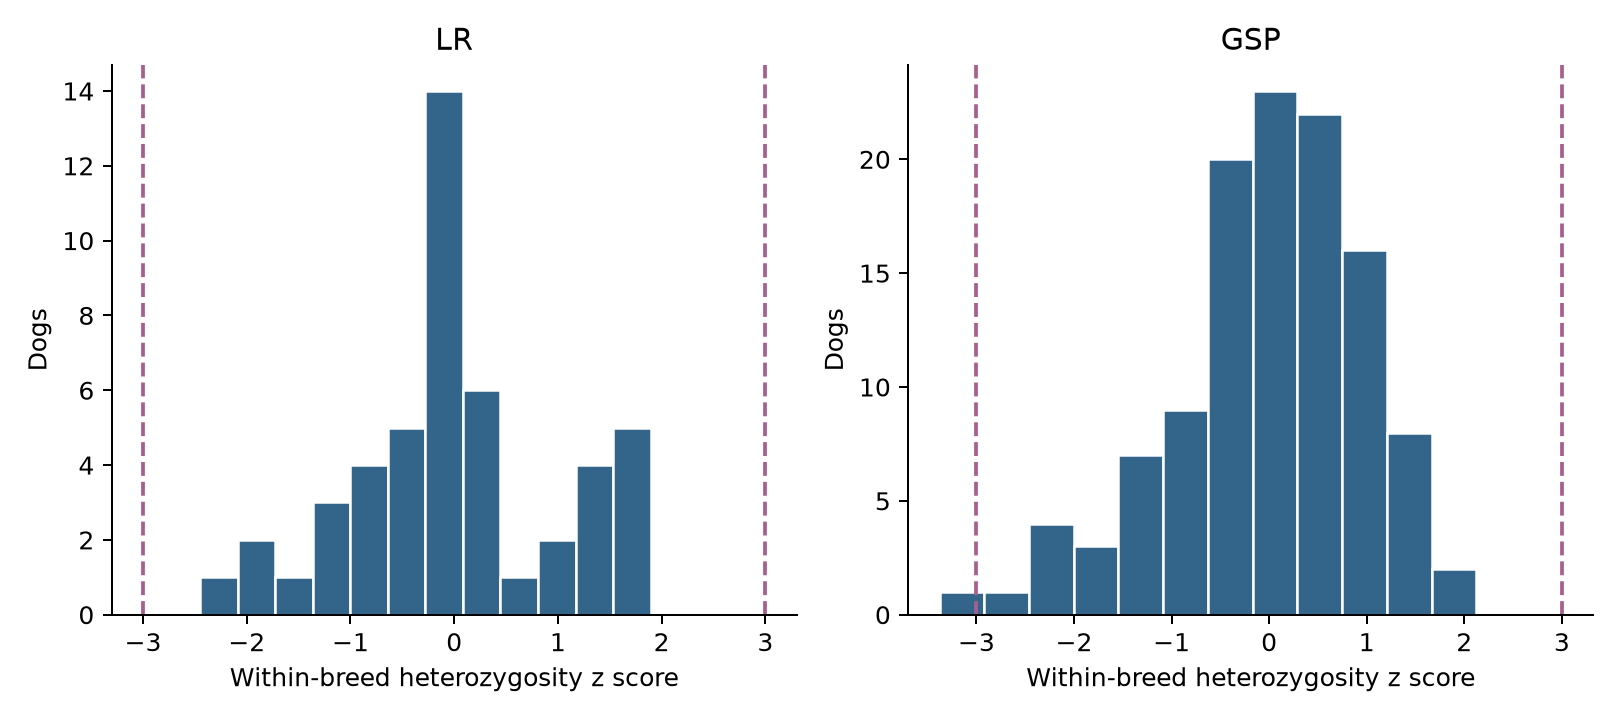

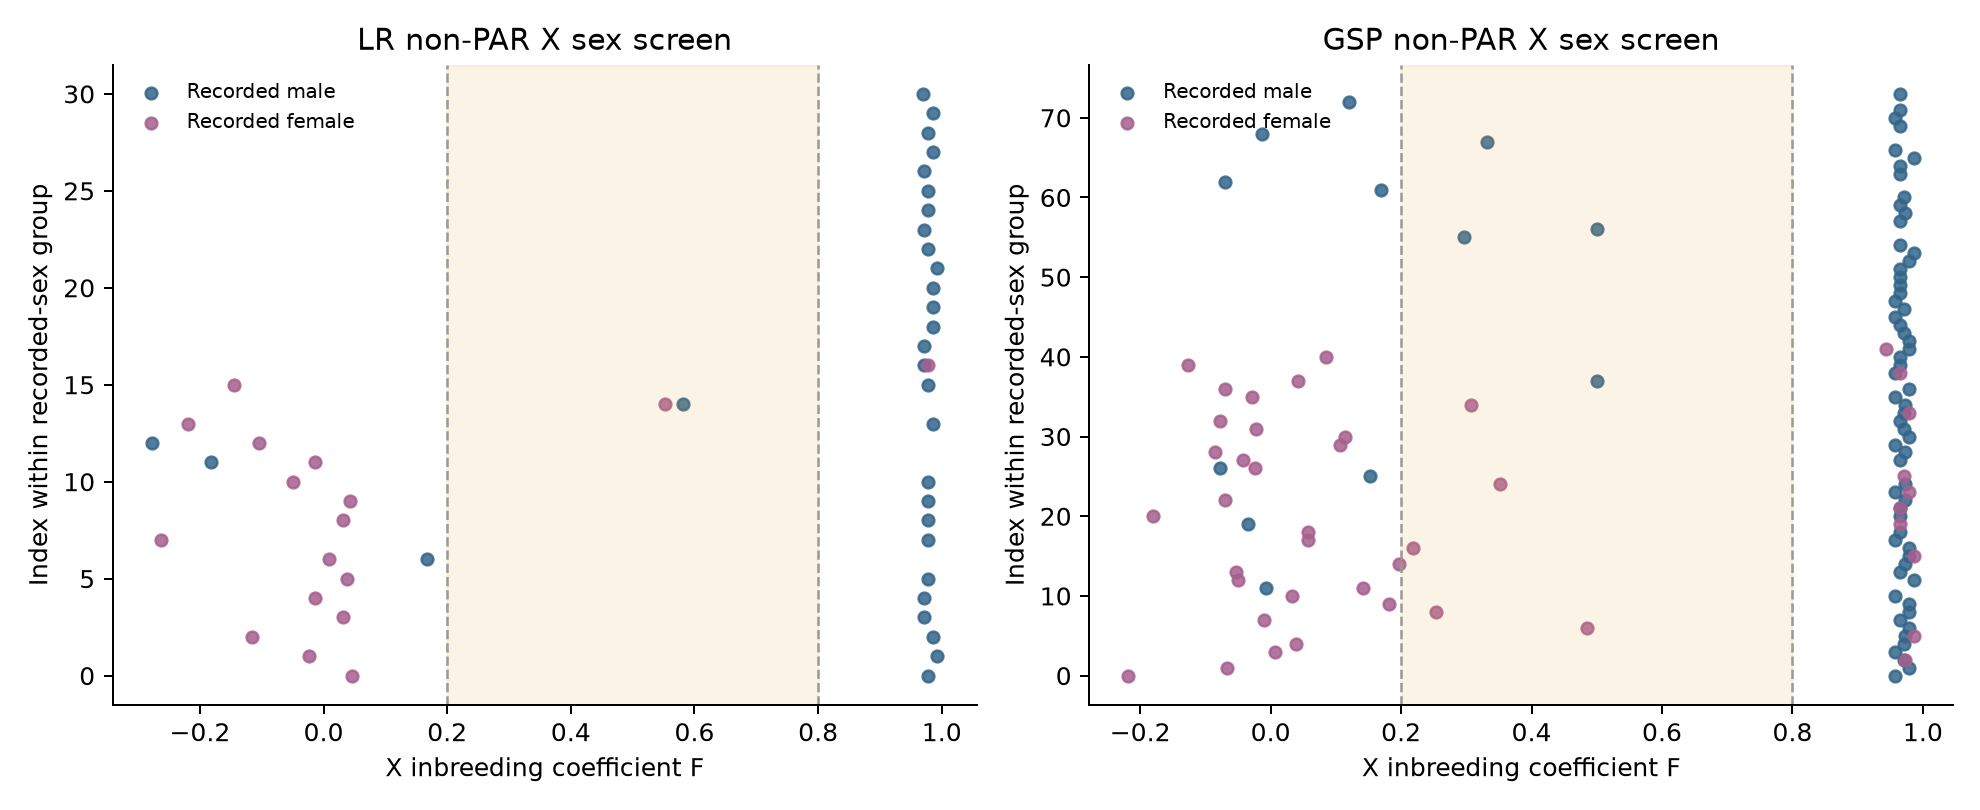

In [6]:
# Draw and display the additional QC figures so flagged patterns can be reviewed alongside the counts.
# Report only the number of private X/Y supporting records, not individual dog measurements.

# Figures are private and use recorded sex without relabeling dogs.
from extension_support import rows as extension_rows
# run_script(study_root, "plot_study_extensions.py", "--stage", "qc")
for filename in ["heterozygosity.png", "sex_screen.png"]:
    figure = qc_diagnostics / filename
    if figure.exists():
        display(Image(filename=str(figure)))
sex_support = extension_rows(qc_diagnostics / "sex_support.private.tsv")